# 🚦 Proyecto de Big Data: <br> Análisis de Fallecidos por Accidentes de Tránsito ($\text{SPPAT}$ $2016 - 2021$)
## 😨 + 🚗 = 💥 $\rightarrow$ 🚨 🚓 😵

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/johnprogra25/proyecto-big-data-sppat/blob/main/Proyecto_Bimestral.ipynb)

> **Descripción:** Cuaderno de trabajo correspondiente a las fases de **Extracción, Exploración ($\text{EDA}$) y Transformación** de datos para el proyecto bimestral.

---

### 🏛️ Información Académica

| Detalle | Descripción |
| :--- | :--- |
| **🏫 Institución** | <br> Escuela Politécnica Nacional ($\text{EPN}$) <br> <br>|
| **📚 Asignatura / Proyecto** | <br> Big Data — Proyecto Bimestral ($\text{SPPAT}$ Ecuador) <br> <br> |
| **👥 Integrantes** | <br> • Esteban López <br><br> • Samuel Crespo <br> <br>• Matías  Lamiña <br> <br> • John Durán <br> |


---

### 📑 Índice y Contenido del Cuaderno

A continuación se detalla el flujo de procesamiento aplicado al conjunto de datos ($N > 16,000$ registros):

| Fase | Sección del Cuaderno | Actividades Principales |
| :---: | :--- | :--- |
|**00**|**👀 Contexto: Siniestralidad Vial**|Introducción al problema, justificación del análisis y contexto general del dataset.|
|**01**|**💻 Descripción de Herramientas**|Presentación del ecosistema de Python (Pandas, NumPy, Matplotlib, Seaborn) utilizado|
| **02** | **📥 Extracción de datos** | Carga del archivo `CSV` direc3amente desde GitHub e inspección inicial de estructura. |
| **03** | **🔍 Exploración de datos ($\text{EDA}$)** | $4$ dimensiones de análisis: género, provincia, tipo de accidente y evolución por año. |
| **04** | **🧹 Transformación de datos** | Limpieza, normalización de cadenas de texto y tratamiento de valores nulos. |
| **05** | **💾 Exportación** | Generación y descarga del dataset procesado (`CSV` limpio) listo para modelado. |

---


# 0. Contexto 👀: Siniestralidad Vial en Ecuador 🇪🇨
---

### 🚦 ¿De qué trata este caso de estudio y qué está pasando en esta área?

El presente proyecto se centra en el análisis de los registros de **siniestros de tránsito en el Ecuador**, utilizando el conjunto de datos del *Sistema Público para Pago de Accidentes de Tránsito (SPPAT)*.

> ⚠️ En la actualidad, la **seguridad vial** es uno de los desafíos más críticos para la **salud pública** y la **infraestructura** del país. A diario se registran incidentes que afectan la integridad de los ciudadanos y generan un fuerte impacto socioeconómico, por lo que existe una necesidad urgente de entender las dinámicas detrás de estos eventos a través de la **ciencia de datos**.

---

### 🎯 ¿Qué se busca analizar y por qué es importante el tema?

El objetivo principal de este proyecto es **explorar, limpiar y analizar** este conjunto de datos masivo para identificar patrones de siniestralidad, como:
* 🚗 Los **tipos de accidentes** más recurrentes.
* 👥 **Variables demográficas**.
* 🌦️ **Condiciones específicas** asociadas a los incidentes.


💡 Este tema es de **vital importancia** porque transformar estos datos crudos en **conocimiento estratégico** permite tomar decisiones basadas en evidencia. Los hallazgos obtenidos pueden servir como base para:
  + 🛡️ Proponer **políticas de prevención** más efectivas.
  + 🚑 Optimizar la **distribución de recursos** de emergencia.
  + 🛣️ Mejorar la **planificación vial**, contribuyendo directamente a la reducción de accidentes en el país.

<div align="center">
  <img src="https://i.pinimg.com/736x/23/67/2e/23672e695ef6fb6b74d6ef29733f391d.jpg" width="400" alt="Gatitos muy locos">
</div>


# 🛠️ 1. Descripción de Herramientas Utilizadas

> **Contexto Tecnológico:** Para llevar a cabo las fases de **Extracción, Exploración (EDA) y Transformación** del dataset de siniestros, se empleó el ecosistema científico de Python. Cada herramienta cumplió un rol específico en el procesamiento de los más de 16,000 registros.

---

### 💻 Librerías y Entorno de Trabajo

| Logo | Herramienta | Uso en el Proyecto |
| :---: | :--- | :--- |
| <img src="https://upload.wikimedia.org/wikipedia/commons/c/c3/Python-logo-notext.svg" width="30"/> | **Python 3** | Lenguaje de programación base ejecutado en el entorno interactivo del cuaderno para orquestar todo el flujo de trabajo. |
| <img src="https://upload.wikimedia.org/wikipedia/commons/e/ed/Pandas_logo.svg" width="70"/> | **Pandas** | Carga de los datos desde el archivo CSV, inspección de la estructura (`shape`, `info`), conversión de tipos de datos (`to_datetime`) y manipulación general del DataFrame. |
| <img src="https://upload.wikimedia.org/wikipedia/commons/3/31/NumPy_logo_2020.svg" width="70"/> | **NumPy** | Soporte matemático esencial para la manipulación de arreglos numéricos de alto rendimiento y el tratamiento de valores nulos durante la limpieza. |
| <img src="https://upload.wikimedia.org/wikipedia/commons/8/84/Matplotlib_icon.svg" width="30"/> | **Matplotlib** | Configuración estructural de las visualizaciones, incluyendo dimensiones (`figsize`), asignación de títulos, etiquetas de ejes y renderizado final. |
| <img src="https://seaborn.pydata.org/_images/logo-mark-lightbg.svg" width="35"/> | **Seaborn** | Desarrollo del análisis exploratorio (EDA) mediante la generación de gráficos estadísticos atractivos (`countplot`, `barplot`, `histplot`) y el manejo de estilos y paletas de colores.[cite: 4] |

---

# 📊 2. Extracción de Datos

> **Fuente Oficial:** Portal de Datos Abiertos del Ecuador — *Fallecidos por accidentes de tránsito registrados por el SPPAT*.

| Parámetro | Detalle del Conjunto de Datos |
| :--- | :--- |
| **📅 Período de captura** | $2016 - 2021$ |
| **📦 Volumen total** | $> 16,000$ registros (Análisis a nivel nacional) |
| **🏛️ Entidad reguladora** | Servicio Público para Pago de Accidentes de Tránsito ($\text{SPPAT}$) |

---

### 📋 Diccionario de Atributos

A continuación se detallan las $10$ variables principales que conforman el *dataset*:

| # | Nombre del Atributo |  Descripción / Valores Posibles |
| :---: | :--- | :--- |
| **1** | `No.` |  Identificador único del registro. |
| **2** | `Género de la víctima` | Sexo biológico o género registrado. |
| **3** | `Estado Civil de la víctima` |  Soltero, casado, unión de hecho, entre otros. |
| **4** | `Condición` | Rol en el siniestro (pasajero, peatón, conductor, etc.). |
| **5** | `Fecha de muerte Víctima` | Fecha exacta del deceso. |
| **6** | `Tipo de accidente` | Naturaleza del evento (atropello, choque, volcado, etc.). |
| **7** | `Fecha Siniestro` |  Fecha en la que ocurrió el evento vial. |
| **8** | `Cantón` |  Ubicación cantonal del suceso. |
| **9** | `Provincia` |  Provincia del Ecuador donde ocurrió el hecho. |
| **10** | `Fecha de creación de Protección` |  Fecha de gestión del trámite o cobertura del SPPAT. |

---

<details>
<summary><b>💡 Nota técnica sobre el volumen de datos (Clic para abrir)</b></summary>
<br>
Dado que el conjunto supera los $N > 16,000$ registros históricos distribuidos en $t \in [2016, 2021]$, permite aplicar técnicas de análisis exploratorio y modelado estadístico robusto a escala país.
</details>

### ✨ Importación de librerias y carga del csv  ✨

In [ ]:
# Importación de librerías esenciales para el análisis y manipulación de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilos para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Carga del conjunto de datos desde el enlace RAW de GitHub
URL = "https://raw.githubusercontent.com/johnprogra25/proyecto-big-data-sppat/main/sppat_fallecidosaccidentestransito_2016-2021.csv"

# Lectura del archivo CSV
df = pd.read_csv(URL, encoding='latin-1')
# Verificación de la cantidad de registros (Mínimo 10.000 registros)
print(f"Dimensiones del dataset (Filas, Columnas): {df.shape}")
print(f"Total de registros: {df.shape[0]}")

# Visualización de las primeras filas
df.head()

Dimensiones del dataset (Filas, Columnas): (16526, 10)
Total de registros: 16526


,No.,Género de la víctima,Estado Civil de la víctima,Condición,Fecha de muerte Víctima,Tipo de accidente,Fecha Siniestro,Cantón,Provincia,Fecha de creación de Protección de Fallecidos
0,1,MASCULINO,SOLTERO/A,PEATÓN,2021/10/17,ATROPELLO,2021/10/17,Mira,Carchi,2021/11/21
1,2,MASCULINO,SOLTERO/A,OCUPANTE,2021/10/31,CHOQUE,2021/10/30,Quito,Pichincha,2021/11/21
2,3,MASCULINO,CASADO/A,OCUPANTE,2021/9/14,CHOQUE,2021/9/14,Shushufindi,Sucumbíos,2021/11/21
3,4,MASCULINO,CASADO/A,OCUPANTE,2020/12/18,VOLCAMIENTO,2020/12/19,Calceta,Manabí,2021/11/21
4,5,MASCULINO,SOLTERO/A,OCUPANTE,2021/10/7,CHOQUE,2021/10/4,Quevedo,Los Ríos,2021/11/21


## 🧐 Descripción básica de los datos 🔍

In [ ]:
# Inspección inicial de tipos de datos y valores nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16526 entries, 0 to 16525
Data columns (total 10 columns):
 #   Column                                         Non-Null Count  Dtype 
---  ------                                         --------------  ----- 
 0   No.                                            16526 non-null  int64 
 1   Género de la víctima                           16526 non-null  object
 2   Estado Civil de la víctima                     16526 non-null  object
 3   Condición                                      16526 non-null  object
 4   Fecha de muerte Víctima                        16526 non-null  object
 5   Tipo de accidente                              16438 non-null  object
 6   Fecha Siniestro                                16526 non-null  object
 7   Cantón                                         16526 non-null  object
 8   Provincia                                      16526 non-null  object
 9   Fecha de creación de Protección de Fallecidos  16526 non-null

# 📊 3. Exploración de Datos (EDA)

> **Enfoque Analítico:** A continuación, se presentan los análisis exploratorios requeridos. Se han desarrollado **4 enfoques clave** que combinan métricas cuantitativas y visualizaciones gráficas para entender a fondo los datos:

----

* 🚻 **Análisis 1 |** Distribución de víctimas mortales según el **Género**.
* 📍 **Análisis 2 |** Identificación de las **Provincias** con mayor incidencia de siniestros viales fatales.
* 💥 **Análisis 3 |** Distribución según el **Tipo de accidente** más frecuente.
* 📅 **Análisis 4 |** Análisis cuantitativo y gráfico de la frecuencia temporal por **Años** (agrupamiento temporal).

---

## ⚥ Género víctimas ⚖️ ❓

In [ ]:
# ANÁLISIS EXPLORATORIO 1: Distribución cuantitativa y gráfica por Género de la víctima
print("--- CONTEO POR GÉNERO ---")
print(df['Género de la víctima'].value_counts(dropna=False))



--- CONTEO POR GÉNERO ---
Género de la víctima
MASCULINO    13542
FEMENINO      2984
Name: count, dtype: int64


/tmp/ipykernel_5172/2615503746.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Género de la víctima', order=df['Género de la víctima'].value_counts().index, palette='viridis')


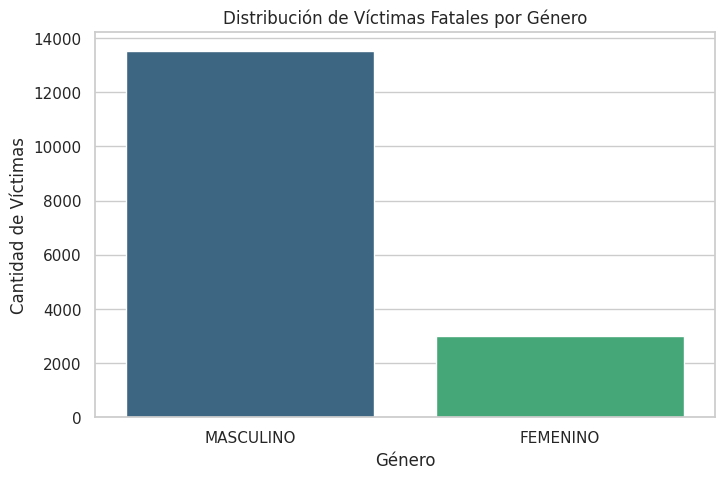

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Género de la víctima', order=df['Género de la víctima'].value_counts().index, palette='viridis')
plt.title('Distribución de Víctimas Fatales por Género')
plt.xlabel('Género')
plt.ylabel('Cantidad de Víctimas')
plt.show()


### 💡 Hallazgo Principal
* 🟦 **Masculino:** `81.94%` (13,542 víctimas mortales)
* 🟥 **Femenino:** `18.06%` (2,984 víctimas mortales)

---

*La amplia mayoría de los registros trágicos en este dataset corresponden a hombres.*

## 🏆 Ranking provincias 📊

In [ ]:
# ANÁLISIS EXPLORATORIO 2: Top Provincias con mayor número de fallecidos
print("--- TOP 10 PROVINCIAS CON MÁS FALLECIDOS ---")
top_provincias = df['Provincia'].value_counts().head(10)
#top_provincias
#display(top_provincias)
print(top_provincias)



--- TOP 10 PROVINCIAS CON MÁS FALLECIDOS ---
Provincia
Guayas                            3697
Pichincha                         2491
Los Ríos                          1440
Manabí                            1386
Cotopaxi                           767
El Oro                             753
Chimborazo                         671
Santo Domingo de los Tsachilas     634
Tungurahua                         604
Azuay                              598
Name: count, dtype: int64


/tmp/ipykernel_5172/410399413.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_provincias.values, y=top_provincias.index, palette='magma')


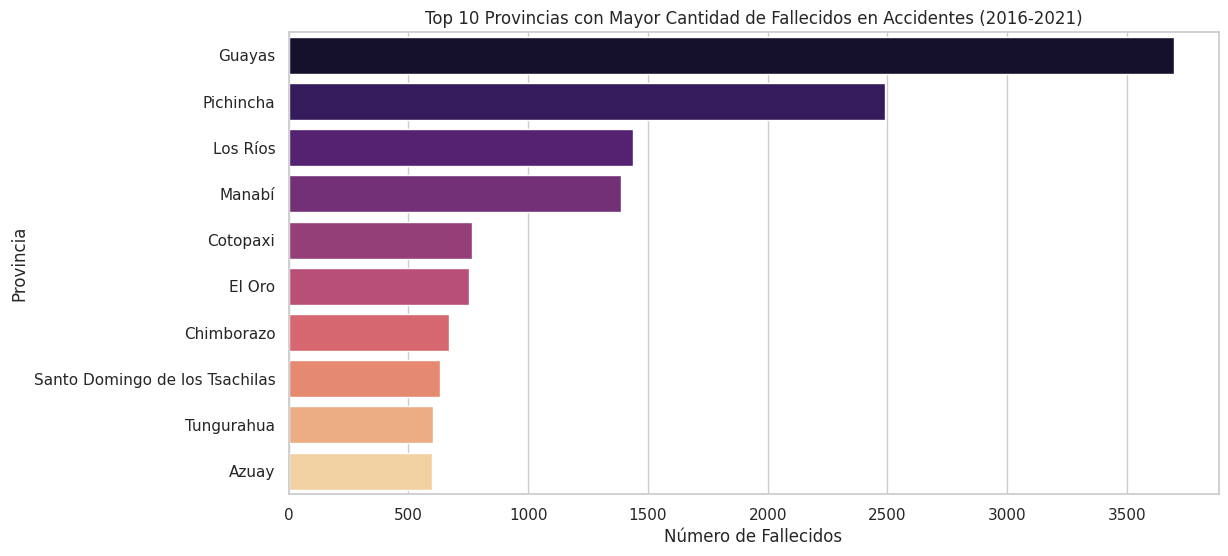

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(x=top_provincias.values, y=top_provincias.index, palette='magma')
plt.title('Top 10 Provincias con Mayor Cantidad de Fallecidos en Accidentes (2016-2021)')
plt.xlabel('Número de Fallecidos')
plt.ylabel('Provincia')
plt.show()

### 📍 Hallazgo Geográfico Principal

* 🔴 **Guayas:** 3,697 víctimas
* 🟠 **Pichincha:** 2,491 víctimas
* 🟡 **Los Ríos:** 1,440 víctimas
* 🟡 **Manabí:** 1,386 víctimas

---

*Nota: Únicamente las dos primeras provincias agrupan el **37.44%** de todos los decesos viales en el país.*

## 🫨 Ranking de accidentes ☹




--- FRECUENCIA POR TIPO DE ACCIDENTE ---
Tipo de accidente
CHOQUE         8527
ATROPELLO      4998
VOLCAMIENTO    2341
CAIDA           409
DESCONOCIDO     163
Name: count, dtype: int64


/tmp/ipykernel_5172/1543854570.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_accidentes.values, y=top_accidentes.index, palette='cubehelix')


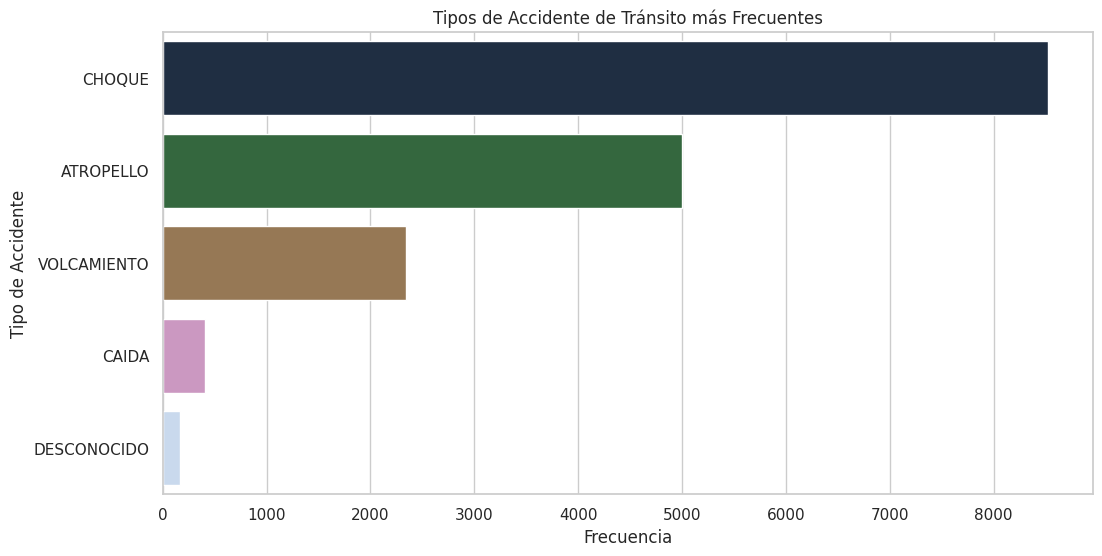

In [ ]:
# ANÁLISIS EXPLORATORIO 3: Tipos de accidente más frecuentes
print("--- FRECUENCIA POR TIPO DE ACCIDENTE ---")
print(df['Tipo de accidente'].value_counts().head(8))

plt.figure(figsize=(12, 6))
top_accidentes = df['Tipo de accidente'].value_counts().head(6)
sns.barplot(x=top_accidentes.values, y=top_accidentes.index, palette='cubehelix')
plt.title('Tipos de Accidente de Tránsito más Frecuentes')
plt.xlabel('Frecuencia')
plt.ylabel('Tipo de Accidente')
plt.show()

### 💥 Hallazgo por Tipo de Evento
* 🚗 **Choque:** 8,527 casos
* 🚶🏽 **Atropello:** 4,998 casos
* 🔄 **Volcamiento:** 2,341 casos

---

*📌 **Acción requerida:** La columna presenta 409 valores nulos que serán gestionados y limpiados en la fase de transformación de datos.*

## ⚠️ Siniestros por año 🚗 📅

--- DISTRIBUCIÓN POR AÑO ---
Anio_Siniestro
2014       7
2015     156
2016    2499
2017    3088
2018    3132
2019    3170
2020    2425
2021    2049
Name: count, dtype: int64


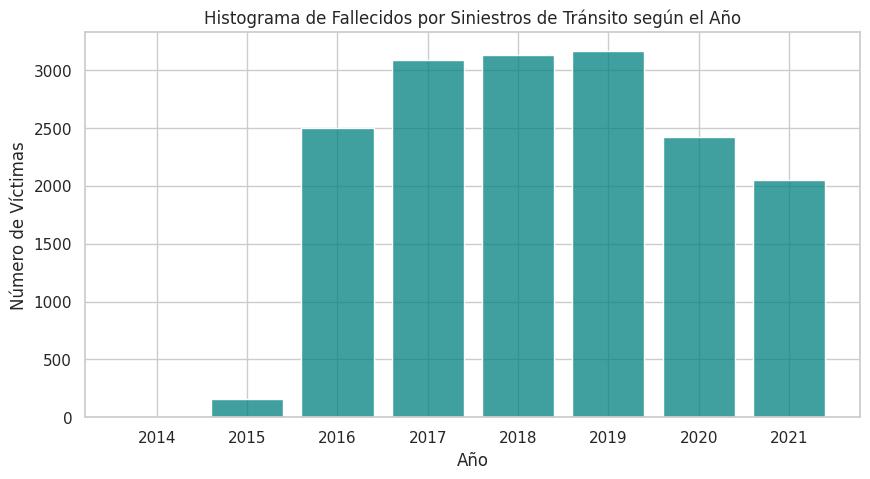

In [ ]:
# ANÁLISIS EXPLORATORIO 4: Extracción de fecha y análisis de tendencia anual (Histograma / Agrupamiento temporal
df['Fecha Siniestro'] = pd.to_datetime(df['Fecha Siniestro'], errors='coerce')
df['Anio_Siniestro'] = df['Fecha Siniestro'].dt.year

print("--- DISTRIBUCIÓN POR AÑO ---")
conteo_anios = df['Anio_Siniestro'].value_counts().sort_index()
print(conteo_anios)

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Anio_Siniestro', discrete=True, color='teal', shrink=0.8)
plt.title('Histograma de Fallecidos por Siniestros de Tránsito según el Año')
plt.xlabel('Año')
plt.ylabel('Número de Víctimas')
plt.show()

### 📅 Hallazgo Temporal
* 📈 **Pico (2017-2019):** Más de 3,000 fallecidos anuales.
* 📉 **Descenso (2020):** 2,425 fallecidos (Efecto pandemia/restricciones de movilidad).

---

*📌 **Datos atípicos:** El dataset contiene registros rezagados pertenecientes a años previos: 7 casos de 2014 y 156 casos de 2015.*

## 🛠️ 4. Transformación de Datos
Para garantizar la calidad de los datos y su correcta preparación para las etapas de modelado, se implementan las siguientes estrategias de limpieza:

> 🧹 **1. Limpieza y normalización de textos**  
> Estandarización de los campos de texto categóricos (como el género o tipo de accidente) convirtiéndolos a mayúsculas y eliminando espacios en blanco sobrantes para evitar duplicidades por errores de formato.


In [ ]:
# TRANSFORMACIÓN 1: Normalización de texto en columnas categóricas (preservando valores nulos reales)
cols_texto = ['Género de la víctima', 'Estado Civil de la víctima', 'Condición', 'Tipo de accidente', 'Cantón', 'Provincia']
for col in cols_texto:
    df[col] = df[col].apply(lambda x: x.strip().upper() if isinstance(x, str) else x)

print("Valores únicos normalizados en 'Género':", df['Género de la víctima'].unique())
print("Valores únicos normalizados en 'Tipo de accidente':", df['Tipo de accidente'].unique())

Valores únicos normalizados en 'Género': ['MASCULINO' 'FEMENINO']
Valores únicos normalizados en 'Tipo de accidente': ['ATROPELLO' 'CHOQUE' 'VOLCAMIENTO' 'DESCONOCIDO' nan 'CAIDA']


> 🗑️ **2. Tratamiento y filtrado de valores nulos**  
> Eliminación de registros donde la fecha del siniestro o las variables clave presenten valores nulos (`NaN`) o inconsistencias temporales que no aporten valor estadístico al análisis.

In [ ]:
# TRANSFORMACIÓN 2: Filtrado y eliminación de registros nulos en campos críticos
filas_iniciales = len(df)

df_limpio = df.dropna(subset=['Fecha Siniestro', 'Provincia', 'Género de la víctima', 'Tipo de accidente']).copy()

filas_finales = len(df_limpio)
print(f"Filas antes de la limpieza: {filas_iniciales}")
print(f"Filas después de la limpieza de nulos: {filas_finales}")
print(f"Registros eliminados por nulos: {filas_iniciales - filas_finales}")

df_limpio.head()

Filas antes de la limpieza: 16526
Filas después de la limpieza de nulos: 16438
Registros eliminados por nulos: 88


,No.,Género de la víctima,Estado Civil de la víctima,Condición,Fecha de muerte Víctima,Tipo de accidente,Fecha Siniestro,Cantón,Provincia,Fecha de creación de Protección de Fallecidos,Anio_Siniestro
0,1,MASCULINO,SOLTERO/A,PEATÓN,2021/10/17,ATROPELLO,2021-10-17,MIRA,CARCHI,2021/11/21,2021
1,2,MASCULINO,SOLTERO/A,OCUPANTE,2021/10/31,CHOQUE,2021-10-30,QUITO,PICHINCHA,2021/11/21,2021
2,3,MASCULINO,CASADO/A,OCUPANTE,2021/9/14,CHOQUE,2021-09-14,SHUSHUFINDI,SUCUMBÍOS,2021/11/21,2021
3,4,MASCULINO,CASADO/A,OCUPANTE,2020/12/18,VOLCAMIENTO,2020-12-19,CALCETA,MANABÍ,2021/11/21,2020
4,5,MASCULINO,SOLTERO/A,OCUPANTE,2021/10/7,CHOQUE,2021-10-04,QUEVEDO,LOS RÍOS,2021/11/21,2021


## 💾 5. Exportación de Datos Procesados

Como paso final del pipeline de este cuaderno, se realiza la exportación del conjunto de datos limpio y transformado (`df_limpio`).

* 📁 **Formato de salida:** Archivo `.csv` local.
* 🎯 **Propósito:** Garantizar que los datos estén listos para ser consumidos por otros componentes del equipo o guardados en almacenamiento en la nube.

---

In [ ]:
# Definición del nombre del archivo de salida
archivo_salida = "sppat_fallecidos_accidentes_limpio.csv"

# Exportación del DataFrame limpio a CSV
df_limpio.to_csv(archivo_salida, index=False, encoding='utf-8')

print(f"¡Dataset exportado exitosamente con el nombre: '{archivo_salida}'!")
print(f"Total de registros listos para exportar/descargar: {len(df_limpio)}")

from google.colab import files
files.download(archivo_salida)

¡Dataset exportado exitosamente con el nombre: 'sppat_fallecidos_accidentes_limpio.csv'!
Total de registros listos para exportar/descargar: 16438


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div align="center">
  <img src="https://i.pinimg.com/736x/de/36/9f/de369f7970ae2fd510bd3288cee830a3.jpg" width="400" alt="Gatitos muy locos">
</div>

```text
                                          ____ ____      _    ____ ___    _    ____  _
                                         / ___|  _ \    / \  / ___|_ _|  / \  / ___|| |
                                        | |  _| |_) |  / _ \| |    | |  / _ \ \___ \| |
                                        | |_| |  _ <  / ___ \ |___ | | / ___ \ ___) |_|
                                         \____|_| \_\/_/   \_\____|___/_/   \_\____/(_)

```